# Path B: class-conditional waveform diffusion

Trains a 1D UNet DDPM directly on raw audio and writes a checkpoint plus generated samples
to Drive. Data, split, crops, training loop, and sampler come from `common.py`, so Path B
sees exactly the same audio crops as Path A. This notebook defines only the waveform
transform and the model.

Set `QUICK_TEST = True` first to run the whole notebook in a few minutes.

## 1. Setup

In [ ]:
!pip install -q diffusers accelerate soundfile

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!ls /content/drive/MyDrive/thesis/

common.py  __pycache__


In [ ]:
import math
import os
import sys

import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from IPython.display import Audio, display

THESIS_DIR = "/content/drive/MyDrive/thesis"   # folder that holds common.py
sys.path.append(THESIS_DIR)
import common as C

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

Device: cuda


## 2. Config

Shared settings come from `C.Config`. Keep `total_steps` equal to Path A's so the paths get
the same training budget.

In [ ]:
QUICK_TEST = False          # True: short run to check the notebook end to end

cfg = C.Config(total_steps=300, inference_steps=20) if QUICK_TEST else C.Config(total_steps=5000)
C.seed_everything(cfg.seed)

# Path B settings
DROPOUT     = 0.1
PATCH       = 4             # consecutive samples folded into channels at the input (1 = none)
CHANNELS    = (64, 128, 256, 256, 256)
COMPAND     = True          # mu-law compress the waveform before diffusion, expand after
MU          = 255.0
GUIDANCE    = 1.0           # keep at 1.0 for distribution metrics
N_PER_CLASS = 2 if QUICK_TEST else 16

RUN_DIR       = f"{cfg.out_root}/path_b_quick" if QUICK_TEST else f"{cfg.out_root}/path_b"
FRONTEND_FILE = f"{cfg.out_root}/frontend.json"          # shared; created by the Path A notebook
WAVE_FILE     = f"{cfg.out_root}/samples/path_b_wave.pt" # generated audio
MEL_FILE      = f"{cfg.out_root}/samples/path_b.pt"      # the same samples as mel, same format as path_a.pt
SAMPLE_SHAPE  = (1, cfg.clip_samples)

down = PATCH * 2 ** (len(CHANNELS) - 1)
assert cfg.clip_samples % down == 0, "clip length must divide by the total downsampling factor"
print(f"clip: {cfg.clip_samples} samples ({cfg.clip_seconds:.2f} s) -> {cfg.clip_samples // down} positions at the bottleneck")

clip: 32512 samples (2.03 s) -> 508 positions at the bottleneck


## 3. Data and waveform transform

Same split and crops as Path A. The mel front end is loaded only to convert generated
audio for evaluation; the model never sees a spectrogram.

**Companding.** Diffusion schedules assume data with a spread comparable to the unit-variance
noise. Peak-normalised audio is mostly near zero, so a raw waveform is drowned by the noise
for most of the schedule. Mu-law companding is an invertible curve that stretches small
amplitudes and keeps everything inside [-1, 1]. The model works in the companded domain and
the output is expanded back to audio. Set `COMPAND = False` to run the raw-waveform ablation.

In [ ]:
data = C.load_esc50(cfg)
train_split, heldout_split = C.split_by_fold(data, cfg)
train_set = C.CropDataset(train_split, cfg)
print(f"train clips: {len(train_split['waveforms'])} | held-out clips: {len(heldout_split['waveforms'])}")

assert os.path.exists(FRONTEND_FILE), "run the Path A notebook first: it creates the shared front end"
frontend = C.MelFrontEnd.load(FRONTEND_FILE, cfg, device=device)

LOG_MU = math.log1p(MU)

def compand(x):
    return torch.sign(x) * torch.log1p(MU * x.abs()) / LOG_MU

def expand(y):
    y = y.clamp(-1, 1)
    return torch.sign(y) * torch.expm1(y.abs() * LOG_MU) / MU

def to_repr(wave):                     # waveform -> what the model is trained on
    return compand(wave) if COMPAND else wave

def to_wave(x):                        # model output -> waveform in [-1, 1]
    return expand(x) if COMPAND else x.clamp(-1, 1)

batch = torch.stack([train_set[i][0] for i in range(64)])
print(f"std of raw waveform: {batch.std():.3f} | std of model input: {to_repr(batch).std():.3f}  (target: roughly 0.3-0.6)")

train clips: 1600 | held-out clips: 400
std of raw waveform: 0.133 | std of model input: 0.432  (target: roughly 0.3-0.6)


## 4. Model

The 1D counterpart of Path A's UNet: the same residual block, the same conditioning, and
attention in the same place. Only the dimensionality changes.

| Choice | Reason |
|---|---|
| Same ResNet block as Path A (GroupNorm, SiLU, scale-shift conditioning) | The comparison should isolate the representation, so the building block is held fixed. |
| Fold 4 samples into channels at the input, unfold at the output | A lossless reshape that cuts the sequence from 32,512 to 8,128. Without it the full-rate layers dominate memory and time. A group of 4 samples is 0.25 ms. |
| Five levels, four 2x downsamples | 8,128 positions are reduced to 508 at the bottleneck. Path A's bottleneck has 512, so attention works over the same number of positions in both paths. |
| Attention only at the coarsest level and the middle | Same placement as Path A. Attention over thousands of positions at higher levels would be too expensive. |
| Channels 64 / 128 / 256 / 256 / 256 | Lands at about 15.9M parameters against Path A's 16.4M, so capacity is matched. |
| Kernel size 3, nearest-neighbour upsampling then a conv | Mirrors Path A. Upsample-then-conv avoids the periodic artefacts of transposed convolutions, which are audible in audio. |
| Class embedding added to the timestep embedding, with a "no label" entry | Same conditioning route as Path A. |

In [ ]:
def _norm(ch):
    return nn.GroupNorm(min(32, ch // 4), ch)


class ResBlock1D(nn.Module):
    """GroupNorm -> SiLU -> conv, twice, with the conditioning applied as scale and shift."""

    def __init__(self, in_ch, out_ch, emb_dim, dropout, kernel):
        super().__init__()
        self.norm1, self.conv1 = _norm(in_ch), nn.Conv1d(in_ch, out_ch, kernel, padding=kernel // 2)
        self.emb = nn.Linear(emb_dim, 2 * out_ch)
        self.norm2, self.conv2 = _norm(out_ch), nn.Conv1d(out_ch, out_ch, kernel, padding=kernel // 2)
        self.dropout = nn.Dropout(dropout)
        self.skip = nn.Conv1d(in_ch, out_ch, 1) if in_ch != out_ch else nn.Identity()

    def forward(self, x, emb):
        h = self.conv1(F.silu(self.norm1(x)))
        scale, shift = self.emb(F.silu(emb)).unsqueeze(-1).chunk(2, dim=1)
        h = self.norm2(h) * (1 + scale) + shift
        h = self.conv2(self.dropout(F.silu(h)))
        return self.skip(x) + h


class AttnBlock1D(nn.Module):
    """Self-attention over time positions, with a residual connection."""

    def __init__(self, ch, head_dim):
        super().__init__()
        self.norm = _norm(ch)
        self.attn = nn.MultiheadAttention(ch, ch // head_dim, batch_first=True)

    def forward(self, x):
        h = self.norm(x).transpose(1, 2)                      # (B, T, C)
        h, _ = self.attn(h, h, h, need_weights=False)
        return x + h.transpose(1, 2)


class UNet1D(nn.Module):
    """1D counterpart of Path A's UNet2DModel: same block design, time axis only."""

    def __init__(self, num_classes, channels=(64, 128, 256, 256, 256), patch=4, layers_per_block=2,
                 dropout=0.1, head_dim=32, kernel=3):
        super().__init__()
        self.patch = patch
        self.base, emb_dim = channels[0], channels[0] * 4
        self.time_mlp = nn.Sequential(nn.Linear(self.base, emb_dim), nn.SiLU(), nn.Linear(emb_dim, emb_dim))
        self.class_emb = nn.Embedding(num_classes + 1, emb_dim)          # +1 = "no label"
        self.conv_in = nn.Conv1d(patch, channels[0], kernel, padding=kernel // 2)

        def res(i, o):
            return ResBlock1D(i, o, emb_dim, dropout, kernel)

        last = len(channels) - 1
        self.down, skip_ch, ch = nn.ModuleList(), [channels[0]], channels[0]
        for lvl, out in enumerate(channels):
            for _ in range(layers_per_block):
                self.down.append(nn.ModuleList([res(ch, out), AttnBlock1D(out, head_dim) if lvl == last else nn.Identity()]))
                ch = out; skip_ch.append(ch)
            if lvl != last:
                self.down.append(nn.Conv1d(ch, ch, 3, stride=2, padding=1)); skip_ch.append(ch)

        self.mid = nn.ModuleList([res(ch, ch), AttnBlock1D(ch, head_dim), res(ch, ch)])

        self.up = nn.ModuleList()
        for lvl, out in reversed(list(enumerate(channels))):
            for _ in range(layers_per_block + 1):
                self.up.append(nn.ModuleList([res(ch + skip_ch.pop(), out), AttnBlock1D(out, head_dim) if lvl == last else nn.Identity()]))
                ch = out
            if lvl != 0:
                self.up.append(nn.Conv1d(ch, ch, 3, padding=1))            # applied after 2x nearest upsampling

        self.norm_out, self.conv_out = _norm(ch), nn.Conv1d(ch, patch, kernel, padding=kernel // 2)

    def forward(self, x, t, labels):
        half = self.base // 2
        freqs = torch.exp(-math.log(10000.0) * torch.arange(half, device=x.device) / half)
        args = t.float()[:, None] * freqs[None]
        emb = self.time_mlp(torch.cat([args.sin(), args.cos()], dim=1).to(x.dtype)) + self.class_emb(labels)

        B, _, T = x.shape
        p = self.patch
        # fold every `p` consecutive samples into channels: (B, 1, T) -> (B, p, T/p). Lossless.
        h = self.conv_in(x.view(B, T // p, p).transpose(1, 2))
        skips = [h]
        for m in self.down:
            if isinstance(m, nn.ModuleList):
                h = m[1](m[0](h, emb))
            else:
                h = m(h)
            skips.append(h)
        h = self.mid[2](self.mid[1](self.mid[0](h, emb)), emb)
        for m in self.up:
            if isinstance(m, nn.ModuleList):
                h = m[1](m[0](torch.cat([h, skips.pop()], dim=1), emb))
            else:
                h = m(F.interpolate(h, scale_factor=2.0, mode="nearest"))
        h = self.conv_out(F.silu(self.norm_out(h)))
        return h.transpose(1, 2).reshape(B, 1, T)             # unfold channels back into samples


def forward_fn(model, x, t, labels):
    return model(x, t, labels)

unet_b = UNet1D(cfg.num_classes, channels=CHANNELS, patch=PATCH, dropout=DROPOUT).to(device)
n_params = sum(p.numel() for p in unet_b.parameters())
print(f"Path B params: {n_params:,}")

Path B params: 15,936,964


## 5. Train

Resumes from `RUN_DIR/last.pt` if it exists. For a run you will report, start from an empty
`RUN_DIR` and do not change `total_steps` partway through.

Resumed from step 5000


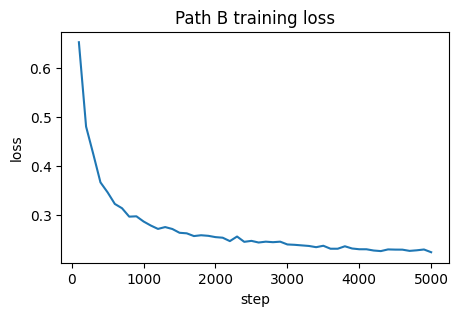

In [ ]:
ema, losses = C.train_diffusion(unet_b, forward_fn, to_repr, train_set, cfg, RUN_DIR, device)

plt.figure(figsize=(5, 3))
plt.plot([cfg.log_every * (i + 1) for i in range(len(losses))], losses)
plt.xlabel("step"); plt.ylabel("loss"); plt.title("Path B training loss")
plt.show()

## 6. Generate and save samples

Two files are written. `WAVE_FILE` holds the generated audio. `MEL_FILE` holds the same
samples passed through the shared mel front end, in the same format as Path A's file, so
the evaluation notebook can treat both paths identically.

In [ ]:
gen_labels = C.balanced_labels(cfg, N_PER_CLASS)
generated = C.sample(unet_b, forward_fn, SAMPLE_SHAPE, cfg, device,
                     labels=gen_labels, ema=ema, guidance=GUIDANCE, batch_size=32)
gen_wave = to_wave(generated)
gen_mel = torch.cat([frontend(gen_wave[i : i + 64]).cpu() for i in range(0, len(gen_wave), 64)])

meta = dict(path="B", guidance=GUIDANCE, steps=cfg.inference_steps, compand=COMPAND, mu=MU,
            patch=PATCH, channels=CHANNELS, n_params=n_params, train_steps=cfg.total_steps)
C.save_samples(WAVE_FILE, gen_wave, gen_labels, cfg, representation="waveform", **meta)
C.save_samples(MEL_FILE, gen_mel, gen_labels, cfg, representation="mel", **meta)
print("saved", tuple(gen_wave.shape), "and", tuple(gen_mel.shape))
print(f"waveform range: [{gen_wave.min():.3f}, {gen_wave.max():.3f}] | std {gen_wave.std():.3f} (real: {batch.std():.3f})")

saved (800, 1, 32512) and (800, 1, 64, 128)
waveform range: [-1.000, 1.000] | std 0.097 (real: 0.133)


## 7. Look and listen

Held-out real clips (top) against generated ones of the same class (bottom), shown as
mel spectrograms, followed by audio players. This is a sanity check only.

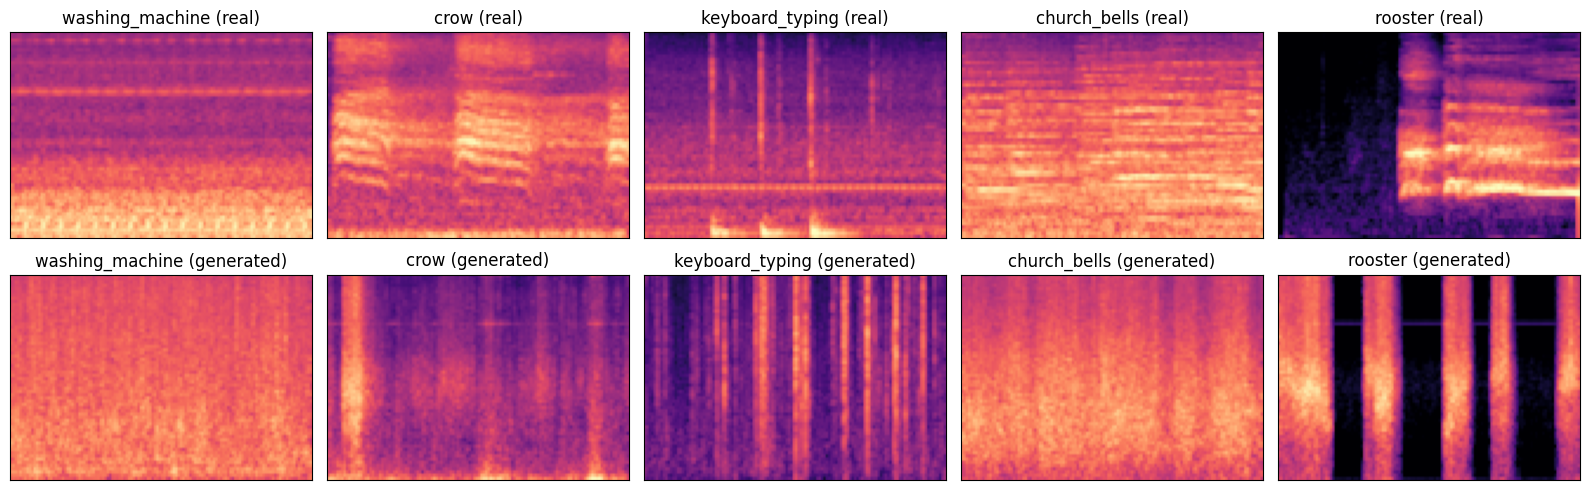

washing_machine - real, then generated


crow - real, then generated


keyboard_typing - real, then generated


In [ ]:
ref_wave, ref_labels = C.reference_crops(heldout_split, cfg, k=1)
show = torch.randperm(cfg.num_classes)[:5].tolist()

fig, axes = plt.subplots(2, 5, figsize=(16, 5))
for col, c in enumerate(show):
    real = frontend(ref_wave[ref_labels == c][:1])[0, 0].cpu()
    fake = gen_mel[gen_labels == c][0, 0]
    for row, (img, tag) in enumerate([(real, "real"), (fake, "generated")]):
        axes[row, col].imshow(img, origin="lower", aspect="auto", cmap="magma", vmin=-1, vmax=1)
        axes[row, col].set_title(f"{data['class_names'][c]} ({tag})")
        axes[row, col].set_xticks([]); axes[row, col].set_yticks([])
plt.tight_layout(); plt.show()

for c in show[:3]:
    print(data["class_names"][c], "- real, then generated")
    display(Audio(ref_wave[ref_labels == c][0, 0].numpy(), rate=cfg.sample_rate))
    display(Audio(gen_wave[gen_labels == c][0, 0].numpy(), rate=cfg.sample_rate))

In [ ]:
peaks = gen_wave.abs().amax(dim=(1, 2))
print(f"clips peaking at >= 0.999: {(peaks >= 0.999).float().mean():.1%}")
print(f"median peak: {peaks.median():.3f} (real clips peak near 0.95 or below)")

clips peaking at >= 0.999: 63.9%
median peak: 1.000 (real clips peak near 0.95 or below)


In [ ]:
real = torch.stack([train_set[i][0] for i in range(800)])
real_peaks = real.abs().amax(dim=(1, 2))

print(f"real clips peaking at >= 0.94:       {(real_peaks >= 0.94).float().mean():.1%}")
print(f"generated clips peaking at >= 0.999: {(peaks >= 0.999).float().mean():.1%}")
print(f"real samples at >= 0.94:             {(real.abs() >= 0.94).float().mean():.4%}")
print(f"generated samples at >= 0.999:       {(gen_wave.abs() >= 0.999).float().mean():.4%}")

real clips peaking at >= 0.94:       55.5%
generated clips peaking at >= 0.999: 63.9%
real samples at >= 0.94:             0.0101%
generated samples at >= 0.999:       0.0179%
